# 6. Train, evaluate and package the model

The main workflow is **04 windows → 05 features → 06 training**. `analysis_mode = "pilot"` permits unmet collection budgets; `"strict"` requires those budgets. Both modes keep the same timing, completeness and parcel-separation checks. No imagery is downloaded here. Previous archives, splits, models and immutable bundles remain preserved.


## 1. Setup and configuration

The default local path reads notebook 05’s saved features without recalculating them. Pilot mode allows unmet sampling budgets, not missing classes or invalid splits. Advanced production keeps its reviewed/frozen input requirements.


In [1]:
from pathlib import Path
import json
import os
import sys
repository_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(repository_root / "src") not in sys.path:
    sys.path.insert(0, str(repository_root / "src"))
os.chdir(repository_root)
from crop_pipeline import analysis_workflow, progress as pipeline_progress
from crop_pipeline.notebook_display import show_table, show_mapping, show_items
from crop_pipeline.sources import adaptive, annual, pilot_sources
from crop_pipeline.windows import seasons as season_workflow
from crop_pipeline.common import save_json
from IPython.display import display

analysis_mode = "pilot"  # pilot: report unmet budgets; strict: require collection targets
analysis_workflow.validate_mode(analysis_mode)
local_settings = json.loads(Path("settings.local.json").read_text()) if Path("settings.local.json").exists() else {}
report_folder = Path(local_settings.get("report_root", "./sen4agrinet_work/inventory")).expanduser().resolve()
source_run_name = local_settings.get("analysis_collection", adaptive.COLLECTION_NAME)
source_manifest_paths, analysis_run_name = pilot_sources.resolve_collection(report_folder, source_run_name)
analysis_folder = report_folder.parent / "analysis" / analysis_run_name
season_folder = analysis_folder / "seasons"
workflow_folder = season_folder / "workflow" / analysis_mode
print("Collection:", source_run_name, "| Mode:", analysis_mode)
print("Workflow folder:", workflow_folder)

from crop_pipeline.features import experiments as feature_experiments
from crop_pipeline.training import exploratory as exploratory_training
from crop_pipeline.training import earth_engine as earth_engine_training
training_mode = "local"  # local | production (advanced reviewed/frozen inputs)
training_run_name = "default"  # Choose a new name for a separate experiment; old results stay intact.
show_figures = True
if not training_run_name or not all(character.isalnum() or character in "_-" for character in training_run_name):
    raise ValueError("Use letters, digits, underscores or hyphens for training_run_name")
if training_mode not in {"local", "production"}:
    raise ValueError("training_mode must be local or production")
stages = ["Load feature handoff", "Check parcel splits", "Fit and evaluate models", "Package selected model", "Summary and next action"]
notebook_progress = pipeline_progress.start_notebook("06_model_training", stages, report_folder.parent / "progress", {"analysis": analysis_run_name, "mode": analysis_mode, "training_mode": training_mode})
comparison_metrics, feature_selections = {}, {}
selected_model_manifest = None


/Users/josedavid/Documents/programming/external-crop-data-classification/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Collection: adaptive_training | Mode: pilot
Workflow folder: /Users/josedavid/Documents/programming/external-crop-data-classification/sen4agrinet_work/analysis/adaptive_training_829e0cec79b8_b671a3d57c17/seasons/workflow/pilot


06_model_training: stages:   0%|          | 0/5 [00:00<?, ?stage/s, elapsed 0m 00s; notebook ETA learning (future stages not yet timed)]

## 2. Load verified features

Require the current feature and window handoffs from the same analysis mode. Never fall back to old CSVs or silently rebuild predictors.


In [2]:
pipeline_progress.begin_stage("Load feature handoff")
analysis_workflow.require_collection_readiness(report_folder, analysis_mode)
if training_mode == "local":
    feature_handoff = analysis_workflow.resolve_stage_pointer(workflow_folder / "feature_stage.json")
    # Also verify that this feature bundle belongs to the current window handoff.
    current_window = analysis_workflow.resolve_stage_pointer(workflow_folder / "window_stage.json")
    feature_rows, configuration, preprocessing_coverage, handoff_manifest = feature_experiments.load_pilot_feature_handoff(feature_handoff)
    if handoff_manifest["identity"]["window_manifest_sha256"] != season_workflow.file_sha256(current_window):
        raise ValueError("Features belong to another window assessment; rerun notebook 05")
    if configuration["analysis_mode"] != analysis_mode:
        raise ValueError("Feature mode differs from the requested training mode")
else:
    feature_handoff = season_folder / "feature_input/feature_handoff.json"
    feature_rows, configuration, preprocessing_coverage, handoff_manifest = feature_experiments.load_feature_handoff(feature_handoff)
print("Feature handoff:", feature_handoff)
pipeline_progress.end_stage()


06_model_training: stages:  20%|██        | 1/5 [00:00<00:01,  2.39stage/s, elapsed 0m 00s; notebook ETA learning (future stages not yet timed)]      

Feature handoff: /Users/josedavid/Documents/programming/external-crop-data-classification/sen4agrinet_work/analysis/adaptive_training_829e0cec79b8_b671a3d57c17/seasons/workflow/pilot/features/b93b9d97a54f40ab/feature_handoff.json


## 3. Check parcel splits

Preserve the locked train/validation/test assignments. Require all three crops in every partition and at least five usable parcel groups per crop overall. Conflicting labels, shared locations, incomplete values and changed locked inputs stop training.


In [3]:
pipeline_progress.begin_stage("Check parcel splits")
if training_mode == "local":
    partitioned_rows, configuration, split_counts, handoff_path = exploratory_training.prepare_feature_inputs(
        feature_handoff, workflow_folder / "models" / training_run_name,
    )
    training_output_folder = handoff_path.parent
    show_table(split_counts, title="Training samples by crop and partition")
else:
    partitioned_rows = feature_rows
    handoff_path = feature_handoff
    training_output_folder = season_folder / "workflow/production" / season_workflow.record_fingerprint({"feature_manifest_sha256": season_workflow.file_sha256(feature_handoff), "implementation": season_workflow.file_sha256(Path(earth_engine_training.__file__))})[:16]
    if handoff_manifest["status"] != "prepared":
        print("Production pending: reviewed fields, independent local labels and frozen window/feature settings are required.")
print("Model folder:", training_output_folder)
pipeline_progress.end_stage()


06_model_training: Check parcel splits:  20%|██        | 1/5 [00:00<00:01,  2.36stage/s, elapsed 0m 00s; notebook ETA learning (future stages not yet timed)]

[{'crop': 'carrot', 'partition': 'train', 'pixels': 103, 'parcel_groups': 6},
 {'crop': 'carrot',
  'partition': 'validation',
  'pixels': 34,
  'parcel_groups': 2},
 {'crop': 'carrot', 'partition': 'test', 'pixels': 20, 'parcel_groups': 1},
 {'crop': 'cabbage', 'partition': 'train', 'pixels': 168, 'parcel_groups': 9},
 {'crop': 'cabbage',
  'partition': 'validation',
  'pixels': 80,
  'parcel_groups': 4},
 {'crop': 'cabbage', 'partition': 'test', 'pixels': 60, 'parcel_groups': 3},
 {'crop': 'potato', 'partition': 'train', 'pixels': 521, 'parcel_groups': 33},
 {'crop': 'potato',
  'partition': 'validation',
  'pixels': 265,
  'parcel_groups': 16},
 {'crop': 'potato', 'partition': 'test', 'pixels': 143, 'parcel_groups': 10}]

06_model_training: stages:  40%|████      | 2/5 [00:00<00:01,  2.50stage/s, elapsed 0m 00s; notebook ETA learning (future stages not yet timed)]             

Model folder: /Users/josedavid/Documents/programming/external-crop-data-classification/sen4agrinet_work/analysis/adaptive_training_829e0cec79b8_b671a3d57c17/seasons/workflow/pilot/models/default/4a20c36f27e4d383


## 4. Fit and evaluate

Train the existing three 1,000-tree Random Forest experiments with equal crop and parcel weighting. Select the design using validation macro-F1 before scoring the external test parcels. Low accuracy does not block completion. Do not choose settings using test scores or future Paoay results.


In [4]:
pipeline_progress.begin_stage("Fit and evaluate models")
if training_mode == "local":
    comparison_metrics, feature_selections = exploratory_training.run_experiments(
        partitioned_rows, configuration, training_output_folder, reuse_completed=True,
    )
    for design, metrics in comparison_metrics["validation"].items():
        print(design, "validation macro-F1:", round(metrics["macro_f1"], 3))
    print("Validation-selected design:", feature_selections["external_parcel_holdout"]["selected_design"])
    for design, metrics in comparison_metrics["test"].items():
        print(design, "held-out accuracy:", round(metrics["accuracy"], 3), "macro-F1:", round(metrics["macro_f1"], 3))
elif partitioned_rows and handoff_manifest["status"] == "prepared":
    import ee
    ee.Initialize(project=local_settings.get("earth_engine_project", ""))
    comparison_metrics, feature_selections = earth_engine_training.train_feature_experiments(
        partitioned_rows, configuration, training_output_folder, ee,
    )
else:
    print("Production training remains pending; pilot readiness does not waive its requirements.")
save_json(training_output_folder / "training_status.json", {"status": "completed" if comparison_metrics else "pending_inputs", "analysis_mode": analysis_mode, "training_mode": training_mode, "feature_selections": feature_selections})
pipeline_progress.end_stage("completed" if comparison_metrics else "pending")


06_model_training: stages:  60%|██████    | 3/5 [00:00<00:00, 9265.77stage/s, elapsed 0m 03s; notebook ETA learning (future stages not yet timed)]                    

interval_only validation macro-F1: 0.411
interval_and_shape validation macro-F1: 0.448
shape_only validation macro-F1: 0.436
Validation-selected design: interval_and_shape
interval_only held-out accuracy: 0.812 macro-F1: 0.592
interval_and_shape held-out accuracy: 0.771 macro-F1: 0.583
shape_only held-out accuracy: 0.637 macro-F1: 0.542


## 5. Package the selected model

Save models, metrics, predictions and provenance. The selected package includes the fitted model, ordered predictors, crop codes, imagery rules, feature policy and exact window recipe. It is an external-data prototype, not a validated Paoay model.


In [5]:
pipeline_progress.begin_stage("Package selected model")
if training_mode == "local" and comparison_metrics:
    selected_model_manifest = exploratory_training.export_selected_model(training_output_folder, feature_handoff)
    print("Selected model package:", selected_model_manifest)
training_coverage = {**preprocessing_coverage, "sample_counts": season_workflow.sample_counts(partitioned_rows),
    "training_status": "completed" if comparison_metrics else "pending_inputs", "feature_selections": feature_selections}
model_artifacts = [path for path in training_output_folder.rglob("*") if path.is_file() and "training_package" not in path.parts]
training_manifest = season_workflow.package_run(
    training_output_folder / "training_package", configuration,
    input_paths=[feature_handoff, handoff_path, Path("requirements-notebooks.txt"), Path("src/crop_pipeline/features/experiments.py"), Path("src/crop_pipeline/training/exploratory.py")],
    artifact_paths=model_artifacts, coverage=training_coverage,
)
pipeline_progress.end_stage("completed" if comparison_metrics else "pending")


06_model_training: stages:  80%|████████  | 4/5 [00:00<00:00, 14.94stage/s, elapsed 0m 03s; notebook ETA learning (future stages not yet timed)]                 

Selected model package: /Users/josedavid/Documents/programming/external-crop-data-classification/sen4agrinet_work/analysis/adaptive_training_829e0cec79b8_b671a3d57c17/seasons/workflow/pilot/models/default/4a20c36f27e4d383/selected_model/1286e2b975ad8fb2/model_manifest.json


## 6. Summary and next action

Read sample coverage, validation selection and held-out errors together. Keep the selected model and preprocessing fixed before evaluating Paoay. Local imagery preparation, classification and ground-truth comparison are the next project stage—not the existing experimental notebooks 07–10. See [training](../docs/training.md).


06_model_training: Summary and next action:  80%|████████  | 4/5 [00:00<00:00, 14.59stage/s, elapsed 0m 03s; notebook ETA learning (future stages not yet timed)]

Status: completed
Metrics and predictions: /Users/josedavid/Documents/programming/external-crop-data-classification/sen4agrinet_work/analysis/adaptive_training_829e0cec79b8_b671a3d57c17/seasons/workflow/pilot/models/default/4a20c36f27e4d383
Selected model: /Users/josedavid/Documents/programming/external-crop-data-classification/sen4agrinet_work/analysis/adaptive_training_829e0cec79b8_b671a3d57c17/seasons/workflow/pilot/models/default/4a20c36f27e4d383/selected_model/1286e2b975ad8fb2/model_manifest.json
Next: keep this model/recipe fixed, prepare matching four-month Paoay inputs, classify, then evaluate against dated local ground truth.
A low score is a reportable pilot result; external test scores do not establish Paoay accuracy.


06_model_training: Summary and next action:  80%|████████  | 4/5 [00:00<00:00,  5.25stage/s, elapsed 0m 04s; notebook ETA learning (future stages not yet timed)]

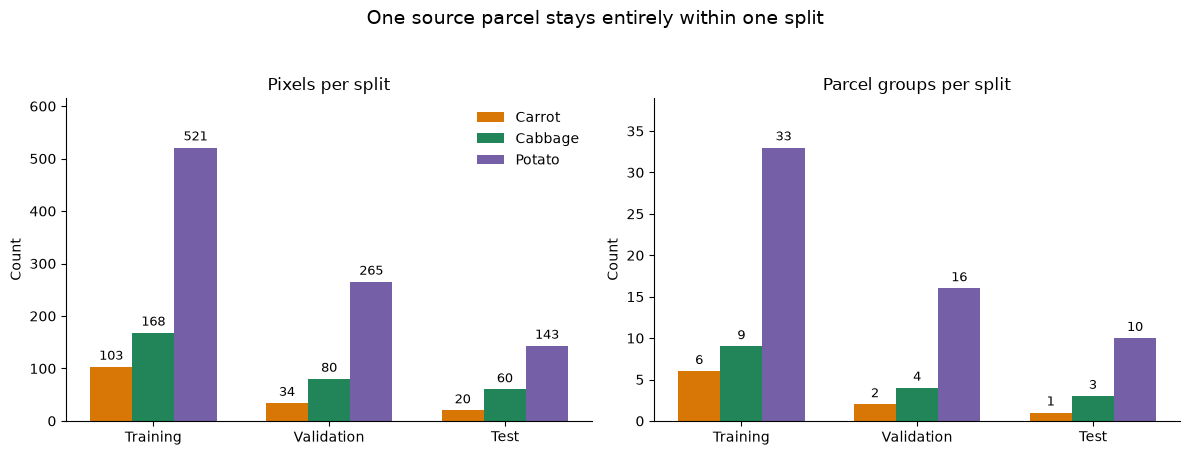

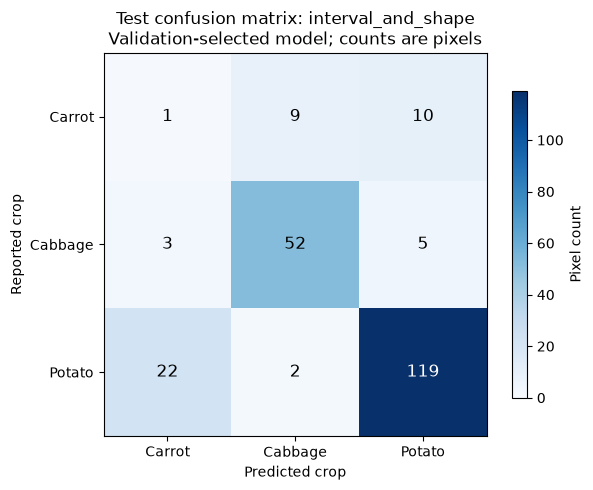

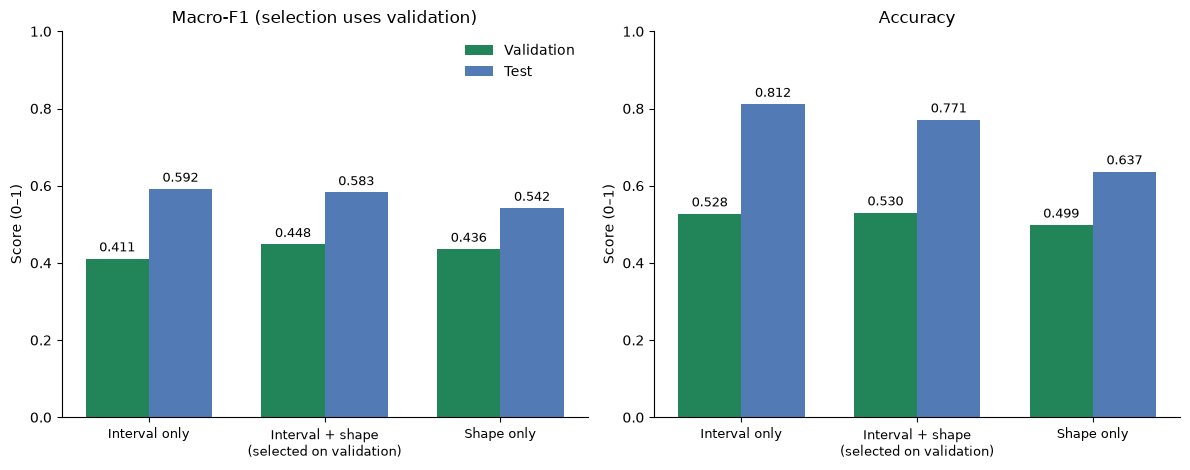

06_model_training: stages: 100%|██████████| 5/5 [00:00<00:00,  5.09stage/s, elapsed 0m 04s; notebook ETA 0m 00s (future stages not yet timed)]                   

All saved figures: /Users/josedavid/Documents/programming/external-crop-data-classification/sen4agrinet_work/analysis/adaptive_training_829e0cec79b8_b671a3d57c17/seasons/workflow/pilot/models/default/4a20c36f27e4d383/visuals
Detail log: /Users/josedavid/Documents/programming/external-crop-data-classification/sen4agrinet_work/progress/06_model_training/runs/20261109T122535_5270bf23.log
06_model_training: 0m 04s elapsed; timing report: /Users/josedavid/Documents/programming/external-crop-data-classification/sen4agrinet_work/progress/06_model_training/runs/20261109T122535_5270bf23.json


In [6]:
pipeline_progress.begin_stage("Summary and next action")
print("Status:", training_coverage["training_status"])
print("Metrics and predictions:", training_output_folder)
if selected_model_manifest:
    print("Selected model:", selected_model_manifest)
    print("Next: keep this model/recipe fixed, prepare matching four-month Paoay inputs, classify, then evaluate against dated local ground truth.")
    print("A low score is a reportable pilot result; external test scores do not establish Paoay accuracy.")
if show_figures and training_mode == "local" and comparison_metrics:
    from crop_pipeline.visualization import pipeline as pipeline_visuals
    import matplotlib.pyplot as plt
    figures = {
        "03_parcel_splits": pipeline_visuals.draw_split_counts(comparison_metrics["split_summary"]),
        "05_test_confusion": pipeline_visuals.draw_confusion(comparison_metrics),
        "06_model_comparison": pipeline_visuals.draw_model_comparison(comparison_metrics),
    }
    figure_folder = training_output_folder / "visuals"
    figure_folder.mkdir(parents=True, exist_ok=True)
    for name, figure in figures.items():
        pipeline_visuals.save_figure(figure, figure_folder, name)
    for key in ("03_parcel_splits", "05_test_confusion", "06_model_comparison"):
        display(figures[key])
    for figure in figures.values():
        plt.close(figure)
    print("All saved figures:", figure_folder)
print("Detail log:", notebook_progress.output.path)
pipeline_progress.end_stage()
pipeline_progress.finish_notebook()
